Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0



Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

In [6]:
import enum
from auxillaryFunctions import *

# build_dir,configType = "build", "Debug"
# moduleDir = os.path.join(build_dir, configType)
# if moduleDir not in sys.path:
#     sys.path.append(moduleDir)

# import cathalTest

#need to map gates to ion channels to neurons
#although if we assume 2 gates per neuron, we can just map gates to neuron 

#we use inverse slope, 1/k, whereas most of the literature uses k. This is because we want to avoid division in the sigmoid function
def genGate(vHalf,vKi,tau0,tau1,th,tkInv,x0=0.0,exponent=1,minOpenness=0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,"th":th,"tkInv":tkInv,"exponent":exponent,"minOpenness":minOpenness}

def genOpenGate():
    return genGate(-1000,1000,100,1000,0,0,x0=1)


def genSynapseGate(xt1,TS):
    xt0 = TS
    xt1 = xt1-xt0
    return genGate(0.5,100,xt0,xt1,0.5,-100)


def genDefaultPlasticSynapseData(gain):
    return {
        "efficacy": 0, #p, unitless
        "conductanceGain": gain, #
        "rate": 0.05, #ms
        "gammaP": 0.12, #p per ms
        "gammaD": 0.078, #p per ms
        "thetaP": 0.68, #Ca mol/L
        "thetaD": 0.33, #Ca mol/L
    }

def genAMPA(TS,baseConductance,conductanceGain = 10):
    #for the synapses to work properly you need to know TS
    #This lets the conductance go instantly from 0 to 1
    
    AMPA = {"name":"AMPAR",
                "ion":"Cation",
            "Erev": 0,
            "conductance": baseConductance,
            "current":0,
            "CaCurrent": 0,
            "gates":{
            "vGate1":genOpenGate(),
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genSynapseGate(7,TS)}} #decay is about 7ms for AMPA and GABA, though it can vary a lot, tbh this could be a random variable
    
    for key,val in genDefaultPlasticSynapseData(conductanceGain).items():
        AMPA[key] = val

    return AMPA

def genGABA(TS,baseConductance,conductanceGain):
    GABA = genAMPA(TS,baseConductance,conductanceGain)
    GABA["Erev"] = -70
    return GABA



def genChannelData(neuronData,synapseData,diffusionList,TS):
    allChannelData = {key:[] for key in genOpenGate().keys()}
    listKeys = ["postNeuron","preNeuron","conductance","Erev","CaCurrent","inputDelay", #channel parameters
                "efficacy","conductanceGain","rate","gammaP","gammaD","thetaP","thetaD", #plasticity parameters
                "diffPostNeuron","diffPreNeuron","diffRate","current","name"] #diffusion parameters
    valueKeys = ["nChannels","nDiffusiveConnections"]

    for key in listKeys:
        allChannelData[key] = []
    for key in valueKeys:
        allChannelData[key] = 0

    #efficacy, conductanceGain, rate, gammaP, gammaD, thetaP, thetaD,
    def addDiffusiveConnection(preNeuron,postNeuron,diffusionRate):
        allChannelData["diffPostNeuron"].append(postNeuron)
        allChannelData["diffPreNeuron"].append(preNeuron)
        allChannelData["diffRate"].append(diffusionRate)
        allChannelData["nDiffusiveConnections"]+=1

    allChannelData["biasCurrents"] = []
    nNeurons = len(neuronData)
    allChannelData["nNeurons"] = nNeurons
    for ind,data in enumerate(neuronData):
        allChannelData["biasCurrents"].append(data["neuronData"]["bias"])
        for channel,channelData in data.items():
            if channel not in ["neuronData"]: #info about the neuron specifically, separate from the channel
                addBasicChannelToSystem(allChannelData,ind,channelData)


    allChannelData["writeIndex"] = np.zeros(nNeurons,dtype=np.int32)
    maxDelayInt = 1 #default to 1
    for group in synapseGroups:
        for conn in group:
            pre,post = conn["pre"],conn["post"]
            synapseData = conn["synapse"]
            delay = conn["delay"] #in ms
            delayInt = int(np.ceil(delay/TS))
            maxDelayInt = max(delayInt,maxDelayInt)
            assert 0<=pre<nNeurons and 0<=post<nNeurons, f"edge out of range {pre},{post}"
            addSynapseToSystem(pre,post,synapseData,delayInt,allChannelData)


    for (e0,e1,diffusionRate) in diffusionList:
        assert e0<nNeurons and e1<nNeurons, f"edge out of range {e0},{e1}"
        addDiffusiveConnection(e0,e1,diffusionRate)
    
    allChannelData["maxDelayInt"] = maxDelayInt
    allChannelData["voltages"] = -75*np.ones(nNeurons,dtype = np.float32) + 1*np.arange(0,nNeurons,dtype=np.float32)
    allChannelData["calciumVals"] = np.zeros(nNeurons,dtype = np.float32)
    # allChannelData["biasCurrents"] = bias*np.ones(nNeurons,dtype = np.float32)
    allChannelData["spikeVals"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["netCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["netCaCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["spikeBuffer"] = np.zeros((nNeurons,maxDelayInt),dtype=bool)

    intKeys = ["preNeuron","postNeuron", "nChannels","diffPostNeuron",
               "diffPreNeuron","nDiffusiveConnections","writeIndex",
               "maxDelayInt","inputDelay","nNeurons"]
    nonArrayKeys = ["nNeurons","maxDelayInt","nChannels","nDiffusiveConnections","name"]
    for key in allChannelData.keys():
        val = allChannelData[key]
        if key in intKeys: arrDtype = np.int32
        else: arrDtype = np.float32

        if key in nonArrayKeys:
            pass
        elif type(val) in [list,tuple]:
            allChannelData[key] = np.ascontiguousarray(val,dtype = arrDtype)
        elif type(val)  == np.ndarray:
            allChannelData[key] = np.ascontiguousarray(val,dtype = val.dtype)
        else:
            print(f"Warning {key} is not a list or tuple") 
    
    return allChannelData


def genSynapseGroup(preRange,postRange,nSynapses,synapse,delay):
    preVals = np.random.randint(preRange[0],preRange[1],nSynapses)
    postVals = np.random.randint(postRange[0],postRange[1],nSynapses)
    synapseData = [{"pre":e0,"post":e1,"synapse":deepcopy(synapse),"delay":delay} for e0,e1 in zip(preVals,postVals)]
    return synapseData


TS = 0.03125
nNeurons = 100
k = 5
nSTN = int(nNeurons/3)
nGPe = nNeurons-nSTN
STNrange = [0,nSTN]
GPeRange = [nSTN,nNeurons]
nSTN_GPe,nGPe_GPe,nGPe_STN = k*nSTN,k*nGPe,k*nGPe
STNbias = -1.5
GPeBias = -0.25

#synapse
STN_GPe = genSynapseGroup(STNrange,GPeRange,nSTN_GPe,genAMPA(TS,baseConductance=0.2,conductanceGain=0),delay=2)
GPe_GPe = genSynapseGroup(GPeRange,GPeRange,nGPe_GPe,genGABA(TS,baseConductance=0.2,conductanceGain=0),delay=1)
GPe_STN = genSynapseGroup(GPeRange,STNrange,nGPe_STN,genGABA(TS,baseConductance=0.3,conductanceGain=0),delay=2)
synapseGroups = [STN_GPe,GPe_GPe,GPe_STN]

#neurons
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()

neuronData = []
for _ in range(nSTN):
    STNdata = deepcopy(STNchannels)
    STNdata["neuronData"]={}
    STNdata["neuronData"]["bias"]=STNbias
    neuronData.append(STNdata)

for _ in range(nGPe):
    GPeData = deepcopy(GPechannels)
    GPeData["neuronData"]={}
    GPeData["neuronData"]["bias"]=GPeBias
    neuronData.append(GPeData)

diffRate = 1.0
diffusionList = []
allChannelData = genChannelData(neuronData,synapseGroups,diffusionList,TS)

runTime = 1000

Elapsed time in seconds: 2.2768554


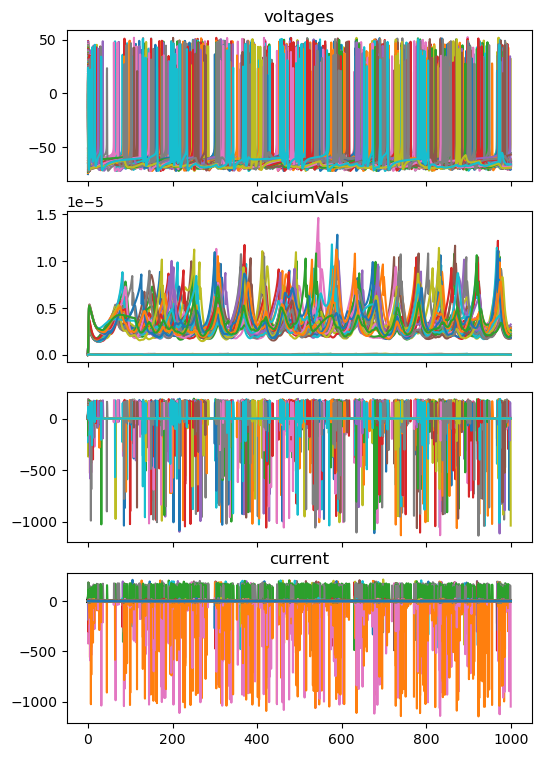

In [7]:

allChannelDataPy = deepcopy(allChannelData)

stimTime = 5
stimInd = int(stimTime/TS)
stimInfo = {}

build_dir,configType = "build", "Release" ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

def solveSystemCpp(ac,TS,runTime,samplingInterval=2, recordingKeys = ["voltages","calciumVals","netCurrent","current"]):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    
    #data = {key:np.zeros([nSamples] + list(ac[key].shape) ) for key in recordingKeys}
    data = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        data[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)

    cathalTest.solveNeuralSystem(ac,data,TS,nIterations,samplingInterval)

    data["time"] = tv
    return data



allChannelDataCpp = deepcopy(allChannelData)
dataCpp = solveSystemCpp(allChannelDataCpp,TS,runTime,samplingInterval=10)
#gatingPlotSideBySide(data,dataCpp)
#sideBySidePlot(data,dataCpp)
standardPlot(dataCpp) #5x worse than real time with 100 neurons #
#20 neurons, 1000ms takes 1.27 seconds. n=100, k=5 took 11 seconds for 1 second, 2 second for release version 